# ERP Analysis With Pandas And Seaborn

We will use the [Steinmetz et al., 2019 in Nature](https://www.nature.com/articles/s41586-019-1787-x) dataset. The experiment involved a mouse being presented with two gradients of varying intensities. The mouse's task was to adjust a wheel to center the brighter gradient on the screen. Simultaneously, Local Field Potential (LFP) measurements were recorded across various brain areas. These measurements were taken 250 times in 2.5 seconds. 

**Analysis goals**

In these exercises, our primary objective is to analyze and visualize Local Field Potential (LFP) data collected from distinct brain regions separately. Through this analysis, we aim to:
  - compute trial statistics on LFP amplitudes (e.g. mean, min, max)
  - compare these statistics between different brain areas
  

**Learning goals**

In this notebook, we'll focus on learning Seaborn's:
  - `sns.catplot()` function for categorical plots
  - `sns.lineplot()` function for plotting time series models
  - `sns.relplot()` for making plots that display relations between different variables in the data
  - `sns.heatmap()` for using colors to compare trends.

## Setup

### Import Libraries

In [2]:
import xarray as xr
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path

## Extracting Data from XArray Datasets into Tidy DataFrames and Plot with Seaborn Catplot

In this section, we'll work with a dataset from a single session recording of Cori the mouse 🐁 ('steinmetz_2016-12-14_Cori.nc'). 

Our primary objective is to read this data and convert it into a Pandas dataframe, which will serve as the foundation for the subsequent exercises.

**Load dataset and convert to Pandas dataframe:**

| Code | Description |
|---|---|
| `dset = xr.load_dataset("path/to/file/like/this.nc")` | Loads the dataset from the specified file path using xarray (`xr`).      |
| `df = dset['column1'].to_dataframe()` | Extracts the 'column1' data variable from the dataset and converts it into a Pandas DataFrame (`df`). |
| `df.reset_index()` | Resets the index of the 'df' DataFrame to create a default integer index. |
| `dset['column1'].to_dataframe().reset_index()` | All of it, together! |
| `dset[['column1', 'column2']].to_dataframe().reset_index()` | Extracts column1 and column2, converts to dataframe, and resets index |
| `sns.catplot(data=df, x='categorical_column_1', y='continuous_column', kind='bar'/'count'/'box'), col='categorical_column_2` | Makes categorical plots of specified kind split into columns based on categories in categorical_column_2 |

Run the code below to make a variable called `dset` by calling by Xarray's `xr.load_dataset()` function on the 'steinmetz_2016-12-14_Cori.nc' session file.  Confirm that the "lfp" data variable is there.



### **Exercises**

**Explore the Data**: Run the following code, and click on the various Coordinates and "Data variables" in the data--there is a lot of data in this file.  Notice that "Data Variables" are defined in terms of "Coordinates"; this makes it so that when we reference them, we'll automatically have coordinate-aligned data.

In [3]:
dset = xr.load_dataset('data/steinmetz_2016-12-14_Cori.nc')
dset

<xarray.Dataset> Size: 118MB
Dimensions:             (trial: 364, time: 250, cell: 734, sample: 82,
                         waveform_component: 3, probe: 384, brain_area_lfp: 7,
                         spike_id: 2446173)
Coordinates:
  * trial               (trial) int32 1kB 1 2 3 4 5 6 ... 360 361 362 363 364
  * time                (time) float64 2kB 0.01 0.02 0.03 0.04 ... 2.48 2.49 2.5
  * cell                (cell) int32 3kB 1 2 3 4 5 6 ... 729 730 731 732 733 734
  * waveform_component  (waveform_component) int32 12B 1 2 3
  * probe               (probe) int32 2kB 1 2 3 4 5 6 ... 380 381 382 383 384
  * brain_area_lfp      (brain_area_lfp) <U4 112B 'ACA' 'LS' ... 'SUB' 'VISp'
  * spike_id            (spike_id) int32 10MB 1 2 3 ... 2446171 2446172 2446173
Dimensions without coordinates: sample
Data variables: (12/31)
    contrast_left       (trial) int8 364B 100 0 100 0 50 0 ... 50 50 0 25 100
    contrast_right      (trial) int8 364B 0 50 50 0 100 0 ... 100 25 25 50 0 100
    gocue               (trial) float64 3kB 1.027 0.8744 0.8252 ... nan nan nan
    stim_onset          (trial) float64 3kB 0.5 0.5 0.5 0.5 ... 0.5 0.5 0.5 0.5
    feedback_type       (trial) float64 3kB 1.0 1.0 1.0 1.0 ... nan nan nan nan
    feedback_time       (trial) float64 3kB 1.187 1.438 0.986 ... nan nan nan
    ...                  ...
    waveform_w          (cell, sample, waveform_component) float32 722kB 0.0 ...
    waveform_u          (cell, waveform_component, probe) float32 3MB 0.0 ......
    lfp                 (brain_area_lfp, trial, time) float64 5MB -2.851 ... ...
    spike_time          (spike_id) float32 10MB 0.2676 2.308 ... 2.189 2.399
    spike_cell          (spike_id) uint32 10MB 1 1 1 1 1 ... 734 734 734 734 734
    spike_trial         (spike_id) uint32 10MB 21 21 31 37 ... 364 364 364 364
Attributes:
    session_date:  2016-12-14
    mouse:         Cori
    stim_onset:    0.5
    bin_size:      0.01

**Example**: Load 'feedback_type' variable and its coordinates as a dataframe.

In [4]:
dset['feedback_type'].to_dataframe().reset_index()

,trial,feedback_type
0,1,1.0
1,2,1.0
2,3,1.0
3,4,1.0
4,5,-1.0
...,...,...
359,360,NaN
360,361,NaN
361,362,NaN
362,363,NaN


**Example**: A picture is worth a thousand words.  Make a count plot for feedback_type, which counting number of values in each "feedback_type" category.

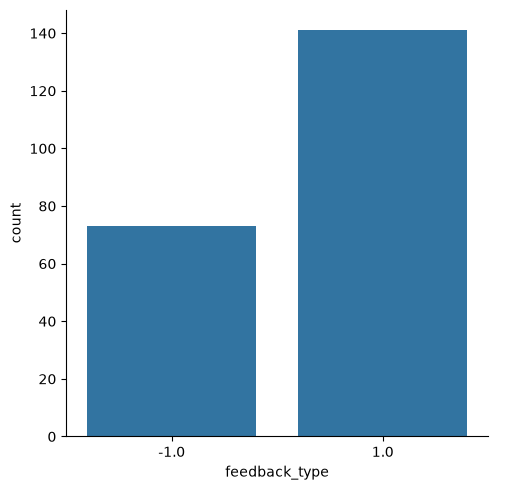

In [5]:
df = dset['feedback_type'].to_dataframe().reset_index()
sns.catplot(data=df, x='feedback_type', kind='count');

**Exercise**: Make a count plot for "response_type", to show what response type codes there are, and how many there are of each in the dataset.

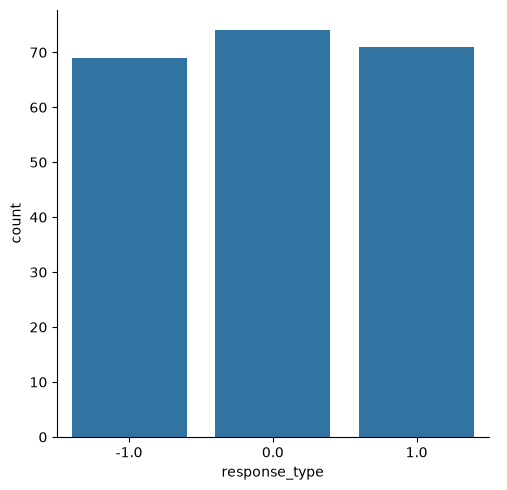

In [6]:
sns.catplot(data = dset['response_type'].to_dataframe().reset_index(), x = 'response_type', kind = 'count'); # how about NaN values 

**Exercise**: What brain areas were recorded from in the dataset?  Make a count for "brain_area".

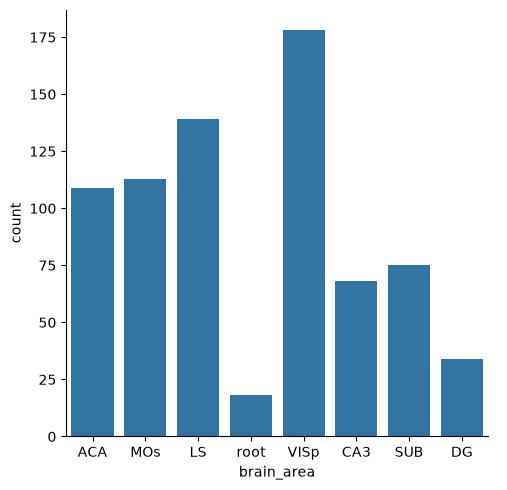

In [7]:
sns.catplot(data = dset['brain_area'].to_dataframe().reset_index(), x = 'brain_area', kind = 'count');

**Example**: Let's start analyzing the data statistically.  Make a bar plot visualizing how mean reaction time varies for different feedback types.

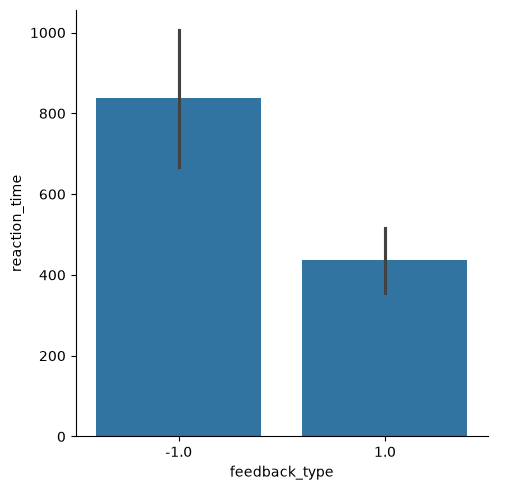

In [8]:
df = dset[['feedback_type', 'reaction_time']].to_dataframe().reset_index()
sns.catplot(data=df, x='feedback_type', y='reaction_time', kind='bar')

**Exercise**: Make a bar plot visualizing how mean **response time** varies for different feedback types.

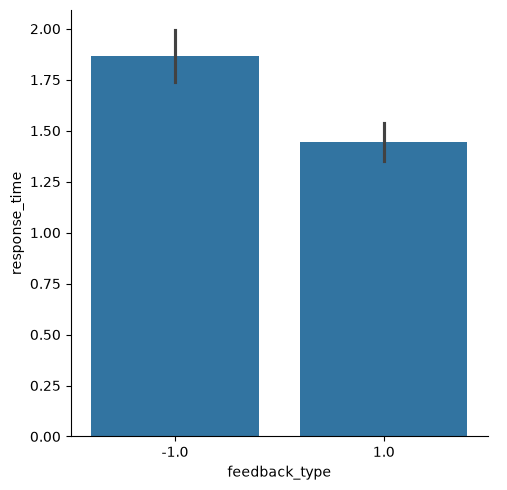

In [9]:
df = dset[['feedback_type', 'response_time']].to_dataframe().reset_index()
sns.catplot(data=df, x='feedback_type', y='response_time', kind='bar')

**Exercise**: Make a bar plot visualizing how mean response time varies for different response types.

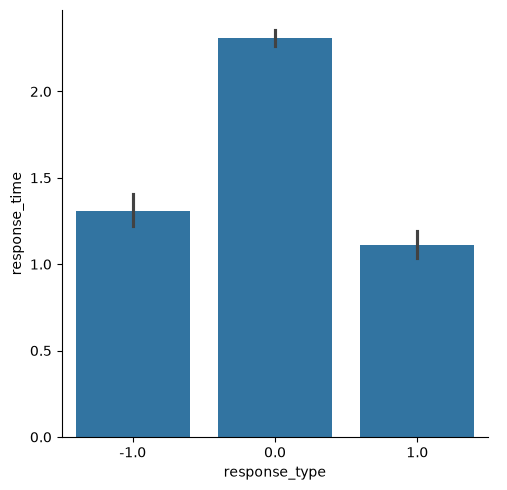

In [10]:
df = dset[['response_type', 'response_time']].to_dataframe().reset_index()
sns.catplot(data=df, x='response_type', y='response_time', kind='bar');

**Exercise**: Make a box plot visualizing how mean response time varies for different response types.

**Hint**: Use `kind='box'`

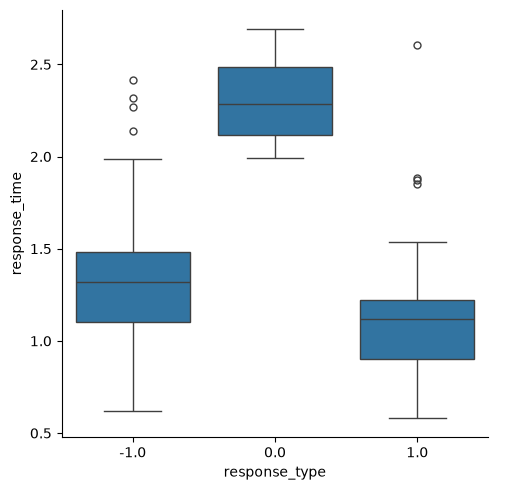

In [11]:
df = dset[['response_type', 'response_time']].to_dataframe().reset_index()
sns.catplot(data=df, x='response_type', y='response_time', kind='box');

**Exercise**: Make a box plot visualizing how mean feedback time varies for different feedback types.

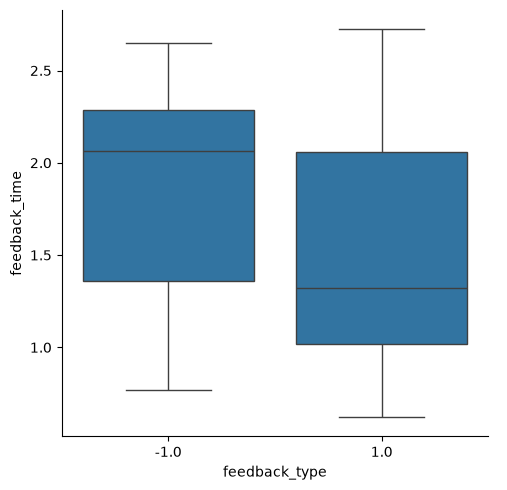

In [12]:
df = dset[['feedback_type', 'feedback_time']].to_dataframe().reset_index()
sns.catplot(data=df, x='feedback_type', y='feedback_time', kind='box');

**Exercise**: Make a box plot visualizing how mean feedback time varies for different feedback types in different columns.

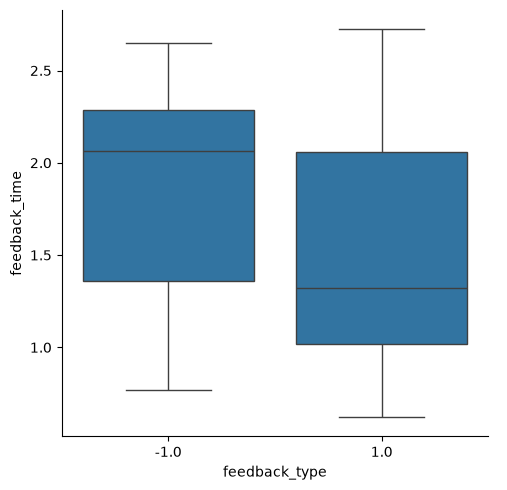

In [13]:
df = dset[['feedback_time', 'feedback_type']].to_dataframe().reset_index()
sns.catplot(data = df, x = 'feedback_type', y = 'feedback_time', kind = 'box');

**Exercise**: Make a box plot visualizing how mean response time varies for different feedback types in different columns

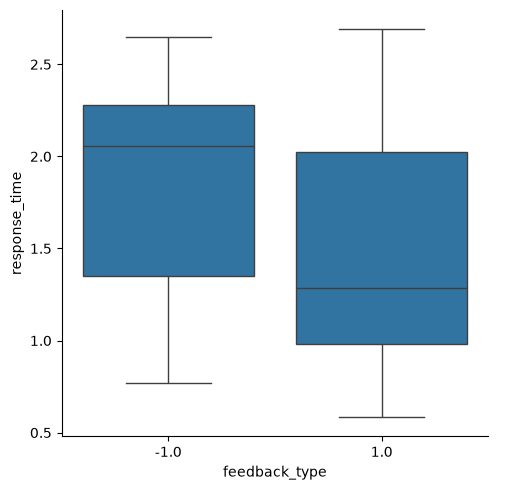

In [14]:
df = dset[['response_time', 'feedback_type']].to_dataframe().reset_index()
sns.catplot(data = df, x = 'feedback_type', y = 'response_time', kind = 'box');

**Exercise**: Make a box plot visualizing how mean feedback time varies for different feedback types  separated into columns based on response types.

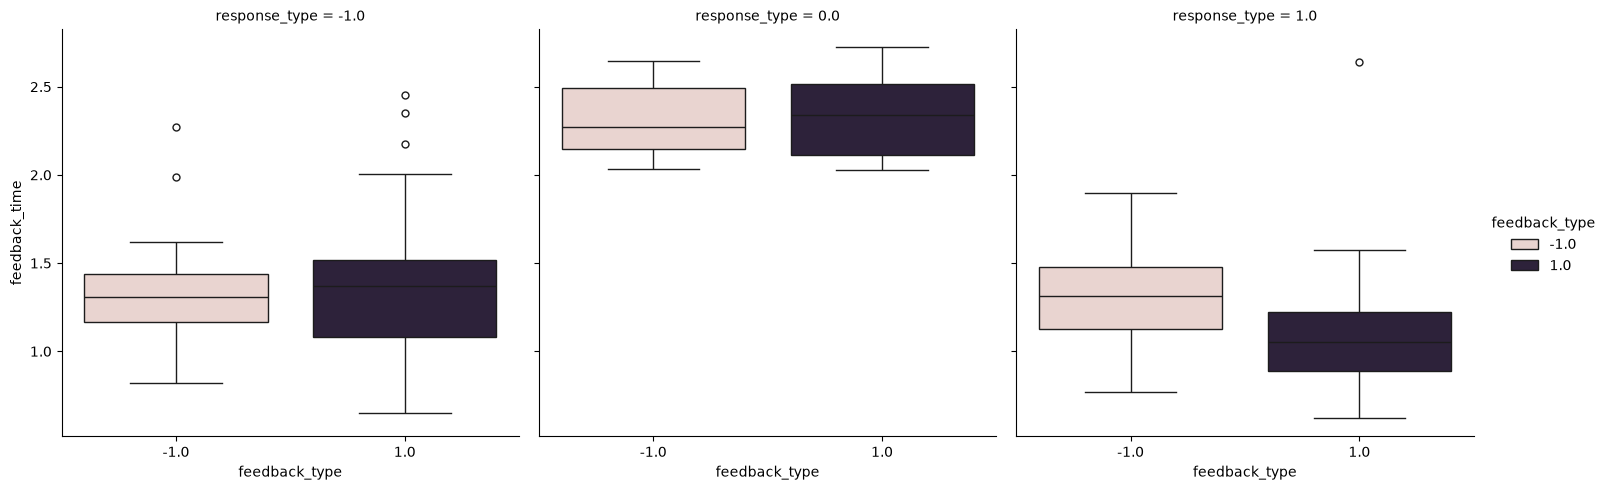

In [15]:
df = dset[['feedback_time', 'feedback_type', 'response_type']].to_dataframe().reset_index()
sns.catplot(data = df, x = 'feedback_type', y = 'feedback_time', hue = 'feedback_type', kind = 'box', col = 'response_type');

**Exercise**: Let's plot this another way. Make a box plot visualizing how mean feedback time varies for different response types separated into columns based on feedback types.

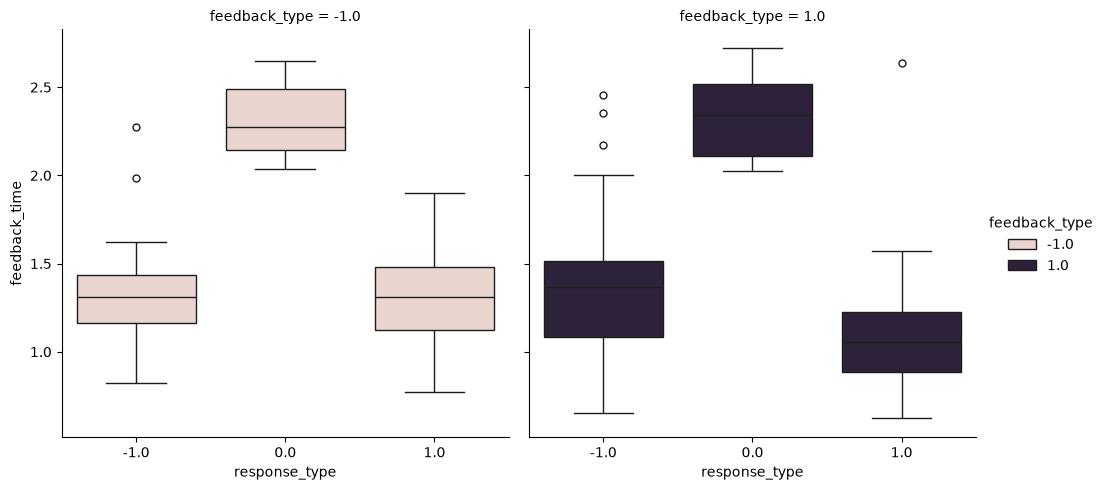

In [16]:
df = dset[['feedback_time', 'feedback_type', 'response_type']].to_dataframe().reset_index()
sns.catplot(data = df, x = 'response_type', y = 'feedback_time', hue = 'feedback_type', kind = 'box', col = 'feedback_type');

**Exercise**: Make a bar plot visualizing how mean lfp varies for different brain areas separated into columns based on feedback types.

In [ ]:
df = dset[['brain_area', 'lfp','feedback_type']].to_dataframe().reset_index() # why does it take so long to run ???


In [ ]:
sns.catplot(data = df, x = 'feedback_type', y = 'lfp', hue = 'brain_area', kind = 'bar', col = 'brain_area');

**Exercise**: Make a bar plot visualizing how mean lfp varies for different brain areas separated into columns based on response types.

In [ ]:
df = dset[['brain_area', 'lfp','response_type']].to_dataframe().reset_index()
sns.catplot(data = df, x = 'response_type', y = 'lfp', hue = 'brain_areas', kind = 'bar', col = 'brain_area');

## Selecting Data based on its Values ("Logical Indexing" or "Masking") and Plotting it in MultiFaceted Line Plots with `sns.relplot()`

Let's analyze continuous data by looking at time series, while adding more steps to our analysis: data filtering.

| Code | Description |
| --- | --- |
| `mask = df["col_1"] == 'val_1'`     | Store which values of `col_1` are equal to `'val_'` |
| `mask = mask1 & mask2` | Store which values are true for both `mask1` and `mask2` |
| `mask = mask1 \| mask2` | Store which values are true for at least one of `mask1` or `mask2` |
| `df[mask]` | Get only the rows of `df` for which the values in `mask` are `True`.  |

##### Plotting MultiFaceted Line Plots with Seaborn: `sns.relplot()`

| Code | Description |
| --- |---|
| `sns.relplot()` | Creates a relational plot using Seaborn. Specifies the following parameters:
| | `data`: DataFrame variable that the plot will be made from.
| | `x=`: Column to use for the x-axis of the plot.
| | `y=`: Column to use for the y-axis of the plot.
| | `kind=`: "line" for a line plot, "scatter" for a scatter plot.
| | `col=`: Column to use to split the figure into columns
| | `col_wrap=`: The max number of columns per row 
| | `n_boot=`: Number of bootstrap resampling to compute confidence intervals.

#### **Exercises**

**Example**: Make a line plot of `time` vs `lfp`, but only for trial numbers less than 50.

In [ ]:
df = dset[['lfp']].to_dataframe().reset_index()
mask = df['trial'] < 50
sns.relplot(data=df[mask], x='time', y='lfp', kind='line', n_boot=20);

**Exercise**: Make a line plot of `time` vs `lfp`, but only for trials where `contrast_left` was `100`

**Exercise**: There seems to be a strong response right after t=0.5.  This is when the visual stimulus appeared in each trial.  Let's see if the response is still there when no stimulus was presented:

Make a line plot of `time` vs `lfp`, but only for trials where `contrast_left` was `0` and `contrast_right` was `0`.

**Exercise**: Make a line plot of `time` vs `lfp`, but only for trials where either `contrast_left` was greater than `50` **or** `contrast_right` was greater than `50`

**Exercise**: Make a line plot of `time` vs `lfp`, but only for `brain_area_lfp` measurements in the visual cortex area `'VISp'`.

**Exercise**: Does the hippocampus have such a distinct response?  Make a line plot of `time` vs `lfp`, but only for `brain_area_lfp` measurements in either `'DG'` or `'CA3'`.

**Exercise**: How does the mouse's response affect the lfp in the visual cortex?  Make a line plot of `time` vs `lfp`, but only for `brain_area_lfp` measurements in the visual cortex area `'VISp'`, and use `hue` to compare the lfp between different `response_type` values.

**Exercise**: There are so many different brain areas; let's plot them all at once in different subplots.  Make a line plot of `time` vs `lfp`, where `col` is the brain area.  (if there are too many columns, you can set `col_wrap=3` to make new rows automatically).

**Exercise**: For each brain area, compare the lfps to different response types.  Which brain areas seem most related to the subject's behavior?

## Visualizing Average LFP Data with Heatmap

Let's try to visualize same information for all brain area in a different format. Sometimes, it might be enough to only see variations in terms of color change rather than number. In this case, a heatmap could be a very informative way to identify patterns in the time series of mean LFP signal across all trials.

We will make use of group-by and pivot_table method of Pandas dataframe to aggregate LFP and Seaborn heatmap method to visualize

| Method | Description |
| --- | --- |
| `mask = df["col_1"] == 'val_1'` | Store which values of `col_1` are equal to `'val_1'`. |
| `mask = mask1 & mask2` | Store which values are true for both `mask1` and `mask2`. |
| `mask = mask1 \| mask2` | Store which values are true for at least one of `mask1` or `mask2`. |
| `df[mask]` | Get only the rows of `df` for which the values in `mask` are `True`. |
| `df.groupby(['column1','column2'])['column3'].mean().unstack()` | Aggregate `column3` with respect to `column1` and `column2` and unstack the table. |
| `df.pivot_table(index='column1', columns='column2', values='column3', aggfunc='mean')` | Does the same as above. |
|`sns.heatmap(grouped_df)`| Create heatmap of grouped_df |

**Example**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time``.

In [ ]:
df = dset['lfp'].to_dataframe().reset_index()
group = df.groupby(['brain_area_lfp', 'time'])['lfp'].mean().unstack()
sns.heatmap(group)

**Exercise**: Make a heatmap visualization of the median Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time``.

**Exercise**: Make a heatmap visualization of the maximum Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time``.

**Exercise**: Make a heatmap visualization of the minimum Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time``.

**Exercise**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time`` but only for ``feedback_type == 1``.

**Exercise**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time`` but only for ``feedback_type == -1``.

We can get the same group with a Pandas method called pivot_table.

**Example**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time`` using pivot_table.

In [ ]:
df = dset['lfp'].to_dataframe().reset_index()
group = df.pivot_table(index='brain_area_lfp', columns='time', values='lfp', aggfunc='mean')
sns.heatmap(group)

**Example**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time`` but only for ``feedback_type == 1`` using pivot table.

In [ ]:
df = dset[['lfp', 'feedback_type']].to_dataframe().reset_index()
mask = df['feedback_type'] == 1
group = df[mask].pivot_table(index='brain_area_lfp', columns='time', values='lfp', aggfunc='mean')
sns.heatmap(group)

**Exercise**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by `brain_area_lfp` and `time` but only for ``response_type == 1``  using pivot table.

**Exercise**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time`` but only for ``feedback_type == -1`` using pivot_table method.

**Exercise**: Make a heatmap visualization of the mean Local Field Potential (LFP) data grouped by ``brain_area_lfp`` and ``time`` but only for ``feedback_type == 1`` and ``response_type == 1`` using pivot_table method